In [9]:
# Install the required packages
!pip install pandas numpy scikit-learn imbalanced-learn torch matplotlib seaborn joblib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [11]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
# from sklearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [ ]:
# Load data
DATA_PATH = "data/creditcard.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df.head())

Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26 

In [22]:
# data validations:
required = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount", "Class"]
)

missing = [
    col for col in required
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

df["Class"] = pd.to_numeric(
    df["Class"],
    errors="coerce"
)

invalid_classes = set(
    df["Class"].dropna().unique()
) - {0, 1}

if invalid_classes:
    raise ValueError(
        f"Unexpected Class values: {invalid_classes}"
    )

print("Dataset is valid.")

print("\nShape:", df.shape)

print("\nMissing values:")
print(df[required].isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass percentage:")
print(
    df["Class"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(
    f"\nFraud percentage: "
    f"{df['Class'].mean() * 100:.3f}%"
)

Dataset is valid.

Shape: (284807, 31)

Missing values:
0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Fraud percentage: 0.173%


Class
0    284315
1       492
Name: count, dtype: int64

In [24]:
df = df.sort_values(
    "Time"
).reset_index(drop=True)

print(df[["Time", "Class"]].head(10))

   Time  Class
0   0.0      0
1   0.0      0
2   1.0      0
3   1.0      0
4   2.0      0
5   2.0      0
6   4.0      0
7   7.0      0
8   7.0      0
9   9.0      0


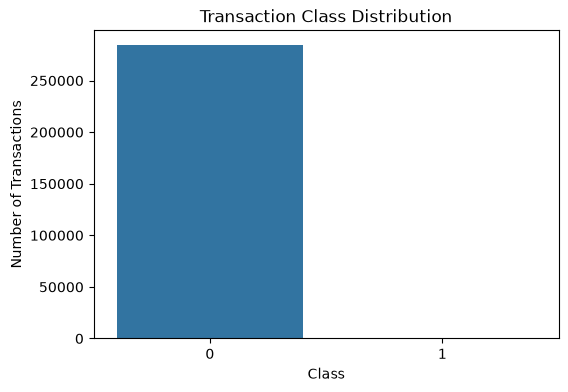

In [25]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Transaction Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")

plt.show()